In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings

In [2]:
# 1. Get list of CSV files (modify folder name if needed)
data_folder = os.path.join(os.getcwd(), "../data")
csv_files = glob.glob(os.path.join(data_folder, "smart_meter_data_*.csv"))
print("Found files:", csv_files)

# 2. Load each CSV into a DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]


Found files: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_0.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_1.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_2.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_3.csv']


In [3]:
warnings.filterwarnings("ignore")

def preprocess_df(dataframes):
    """
    Preprocess a list of DataFrames:
      - Print missing values per column.
      - Convert the 'time' column to datetime with UTC conversion.
      - Remove timezone info, sort the DataFrame by 'time' and reset the index.
      - Drop the 'id' column if present.
      - Create new time-related features: hour, minute, second, day, and month.
    """
    processed = []
    for idx, df in enumerate(dataframes, start=1):
        print(f"\nDataFrame {idx}:")
        
        # Print missing value percentages and column names.
        missing_pct = df.isnull().mean() * 100
        print("Percentage of missing values per column:")
        print(missing_pct)
        print("Columns in DataFrame:")
        print(df.columns.tolist())
        
        # Convert 'time' column to datetime with UTC conversion.
        df['time'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
        if df['time'].isnull().any():
            print("Warning: Some 'time' values could not be converted and are NaT!")
        # Remove timezone information (naive datetime)
        df['time'] = df['time'].dt.tz_convert(None)
        df.sort_values('time', inplace=True)
        df.reset_index(drop=True, inplace=True)
        
        # Drop the 'id' column if it exists.
        if 'id' in df.columns:
            df = df.drop(columns=['id'])
        
        # Create time-based features.
        df['hour'] = df['time'].dt.hour
        df['minute'] = df['time'].dt.minute
        df['second'] = df['time'].dt.second
        df['day'] = df['time'].dt.day
        df['month'] = df['time'].dt.month
        
        processed.append(df)
    return processed

def concat_dataframes_by_time(dataframes):
    """
    Concatenate a list of DataFrames into a single DataFrame and order the rows by 'time'.
    """
    combined_df = pd.concat(dataframes, ignore_index=True)
    combined_df['time'] = pd.to_datetime(combined_df['time'], errors='coerce')
    combined_df.sort_values('time', inplace=True)
    combined_df.reset_index(drop=True, inplace=True)
    return combined_df

def get_complete_time_series(df):
    """
    Group the concatenated DataFrame by device_id and serial_number,
    then return a list of groups (DataFrames) that have no missing values.
    """
    complete_series = []
    grouped = df.groupby(['device_id', 'serial_number'])
    
    ''' # List of device_id, serial_number combinations to skip
    exclude_ids = [
    ('2659da1f-9042-45c0-bf0a-625106aff7d1'),
    ('231e45ef-ca7a-4f80-be11-ac7e2da0274c'),
    ('a806abdf-9261-4d98-abd4-a519248214f0'),
    ('c72b9342-827b-484c-a16a-1b4019f47720'),
    ('fc529a25-d538-4c5b-b51e-2f27a3ce9f1a')
    ]
    '''
    for (device, serial), group in grouped:
        # Skip specified time series by device_id, serial_number combination
        #if (device) in exclude_ids:
        #    print(f"Skipping time series for device_id: {device}, serial_number: {serial} based on exclusion criteria.")
        #    continue
        
        # Ensure the group is sorted by time.
        group_sorted = group.sort_values('time')
        
        # Skip groups with any missing data.
        if group_sorted.isnull().any().any():
            print(f"Skipping time series for device_id: {device}, serial_number: {serial} due to missing data.")
            continue
        
        complete_series.append(group_sorted)
    return complete_series

def add_lag_features(df, columns, lag_freqs={'lag_1h':'1H', 
                                             'lag_12h':'12H', 
                                             'lag_24h':'24H', 
                                             'lag_1w':'7D'}):
    """
    Add lag features for the specified columns based on time differences.
    - First, adds a simple one-row lag.
    - Then, adds time-based lags using pd.merge_asof for given lag frequencies.
    """
    # Create a copy of the DataFrame to avoid modifying the original data.
    df = df.copy()
    
    # Ensure that the 'time' column is converted to datetime format.
    # If there are errors during conversion, they are coerced to NaT (Not a Time).
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # Sort the DataFrame by the 'time' column in ascending order.
    df.sort_values('time', inplace=True)
    
    # ---------------------------
    # Simple one-row lag: Shift each specified column by 1 row.
    for col in columns:
        df[f'{col}_lag_1'] = df[col].shift(1)
    
    # ---------------------------
    # Time-based lags using pd.merge_asof:
    for suffix, lag_str in lag_freqs.items():
        lag_delta = pd.Timedelta(lag_str)
        df[f'time_shift_{suffix}'] = df['time'] - lag_delta
        temp = df[['time'] + columns].copy()
        rename_dict = {col: f'{col}_{suffix}' for col in columns}
        temp.rename(columns=rename_dict, inplace=True)
        merged = pd.merge_asof(
            df.sort_values(f'time_shift_{suffix}'),
            temp.sort_values('time'),
            left_on=f'time_shift_{suffix}',
            right_on='time',
            direction='backward',
            tolerance=pd.Timedelta(lag_str)
        )
        for col in columns:
            df[f'{col}_{suffix}'] = merged[f'{col}_{suffix}'].values
        
        df.drop(columns=[f'time_shift_{suffix}'], inplace=True)
    
    return df

# ---------------------------
# Main Processing Workflow
# ---------------------------

# 1. Preprocess each DataFrame.
processed_dfs = preprocess_df(dataframes)

# 2. Concatenate the processed DataFrames by time.
data_concat = concat_dataframes_by_time(processed_dfs)

# 3. Drop the column with 100% missing values (e.g., 'values_state').
data_concat.drop(columns='values_state', inplace=True, errors='ignore')

# 4. Group the data by device_id and serial_number, extracting only complete time series.
complete_time_series = get_complete_time_series(data_concat)
print(f"Number of complete time series: {len(complete_time_series)}")

# NEW: define exactly the lags & columns you want
lag_args = {
    'lag_5m':   '5T',
    'lag_1h':   '1H',
    'lag_24h':  '24H',
    'lag_168h': '168H'
}

columns_to_add_lag = [
    'total_power_active', 'total_power_reactive', 'total_power_apparent',
    'import_energy_active', 'export_energy_active',
    'import_energy_reactive', 'export_energy_reactive',
    'total_energy_active', 'total_energy_reactive'
]

# 5. For each complete time series, apply lag feature engineering.
processed_time_series = []
for ts in complete_time_series:
    ts_lagged = add_lag_features(
        ts,
        columns=columns_to_add_lag,
        lag_freqs=lag_args
    )
    processed_time_series.append(ts_lagged)

print(f"Processed {len(processed_time_series)} time series with lag features.")



DataFrame 1:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
total_power_reactive        0.0
total_power_apparent        0.0
import_energy_active        0.0
export_energy_active        0.0
import_energy_reactive      0.0
export_energy_reactive      0.0
total_energy_active         0.0
total_energy_reactive       0.0
dtype: float64
Columns in DataFrame:
['time', 'device_id', 'serial_number', 'values_state', 'total_power_active', 'total_power_reactive', 'total_power_apparent', 'import_energy_active', 'export_energy_active', 'import_energy_reactive', 'export_energy_reactive', 'total_energy_active', 'total_energy_reactive']

DataFrame 2:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
tota

Processing time series for device 1


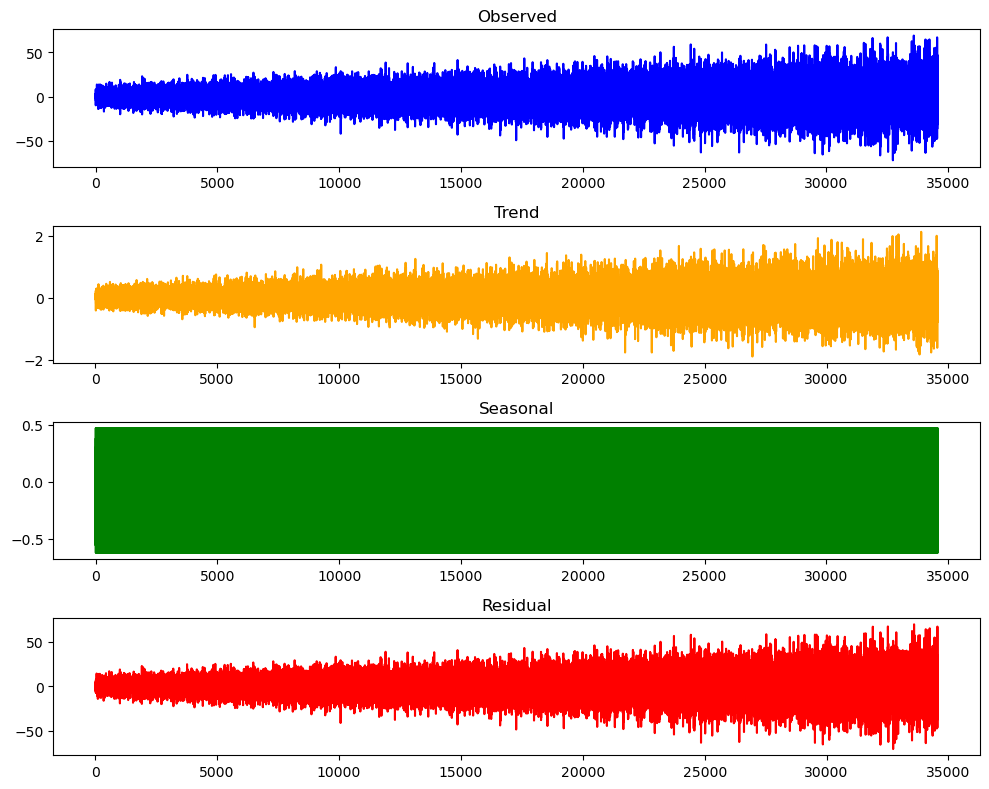

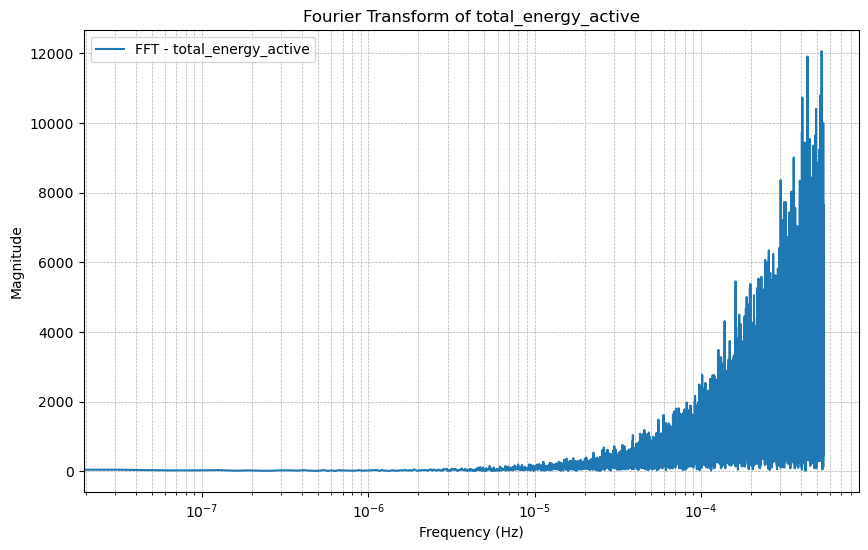

Processing time series for device 2


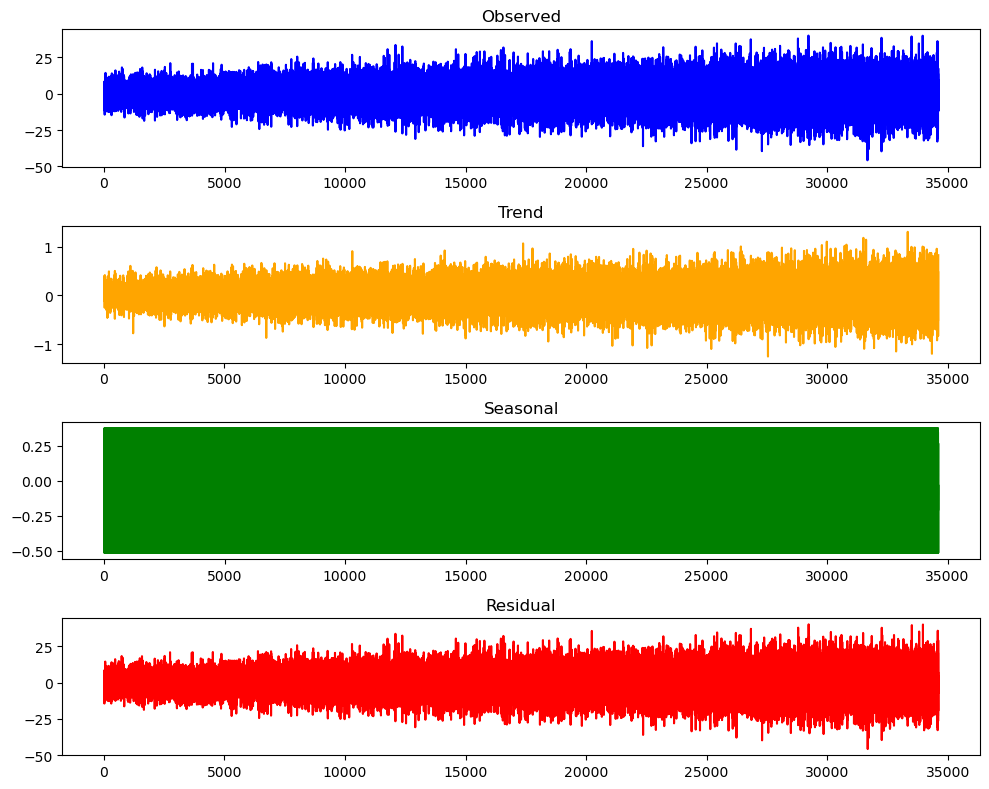

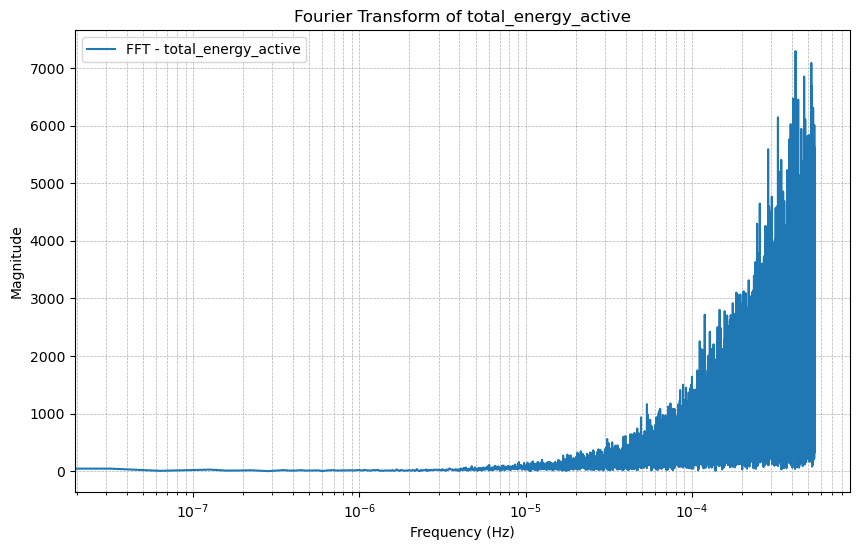

Processing time series for device 3


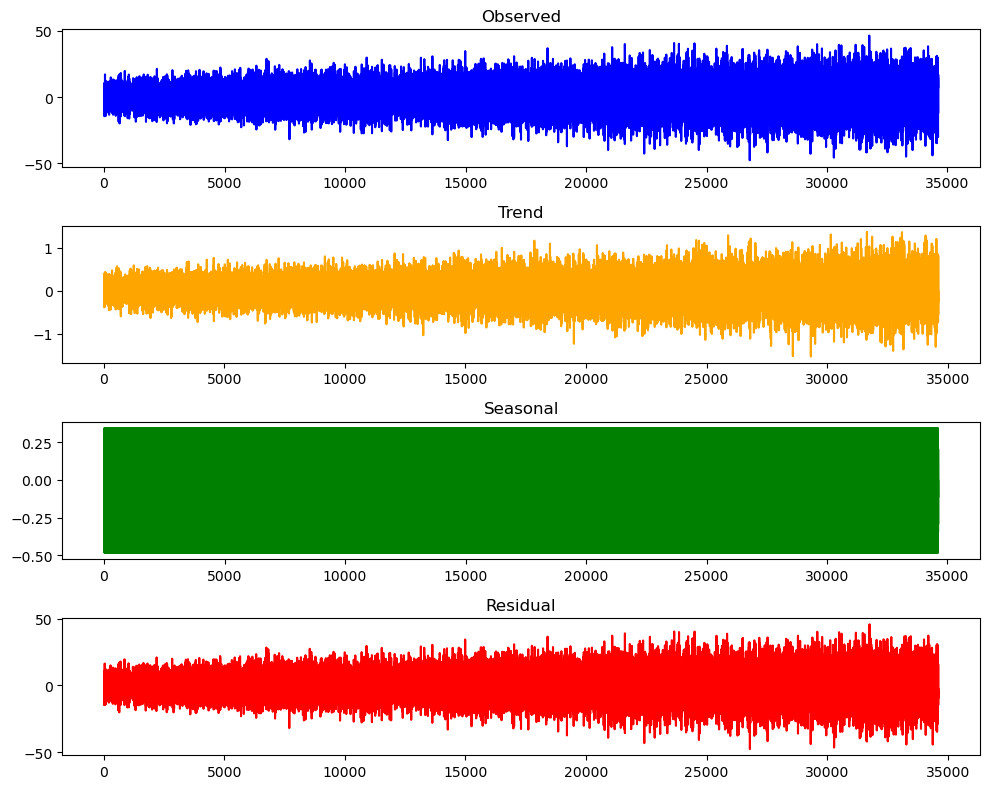

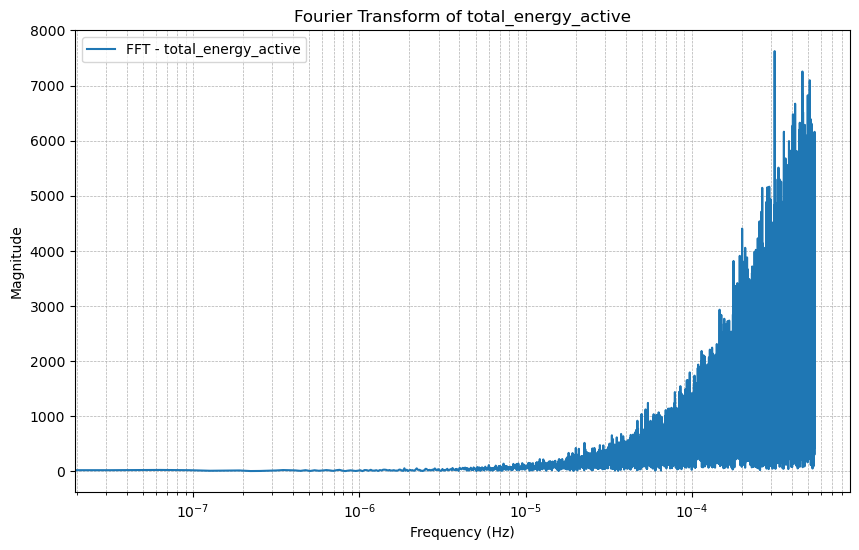

Processing time series for device 4


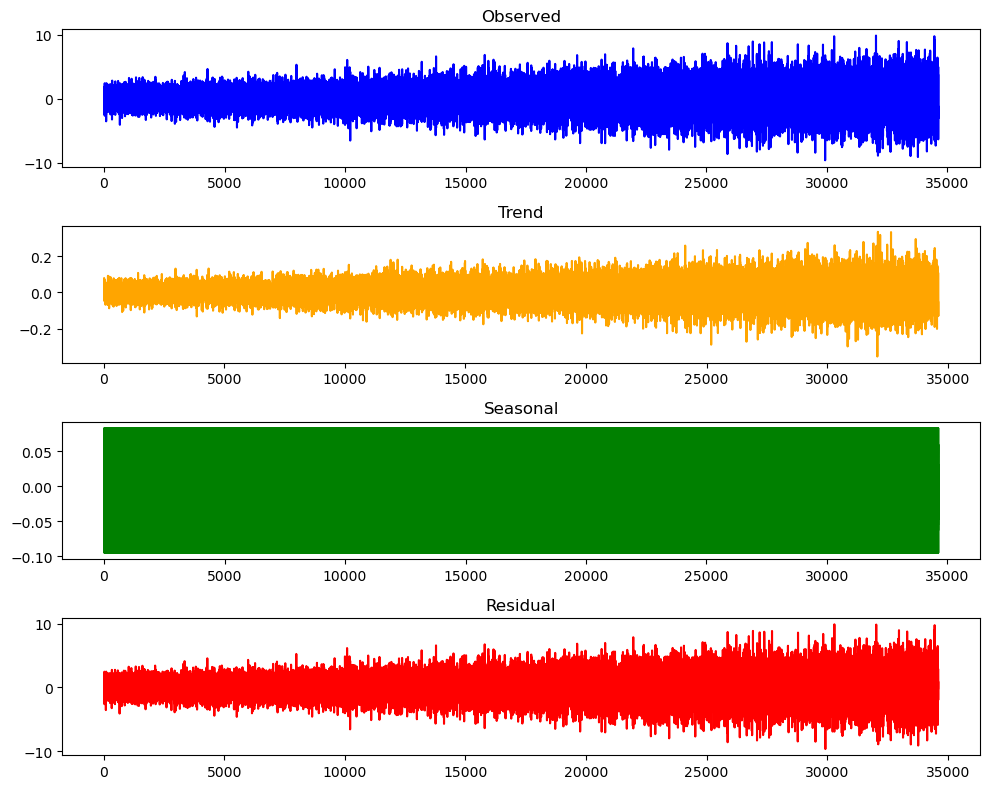

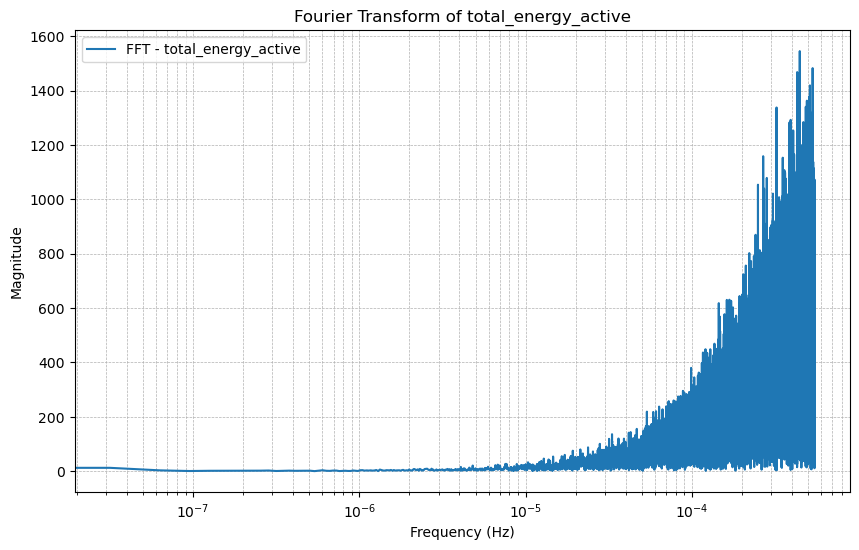

Processing time series for device 5


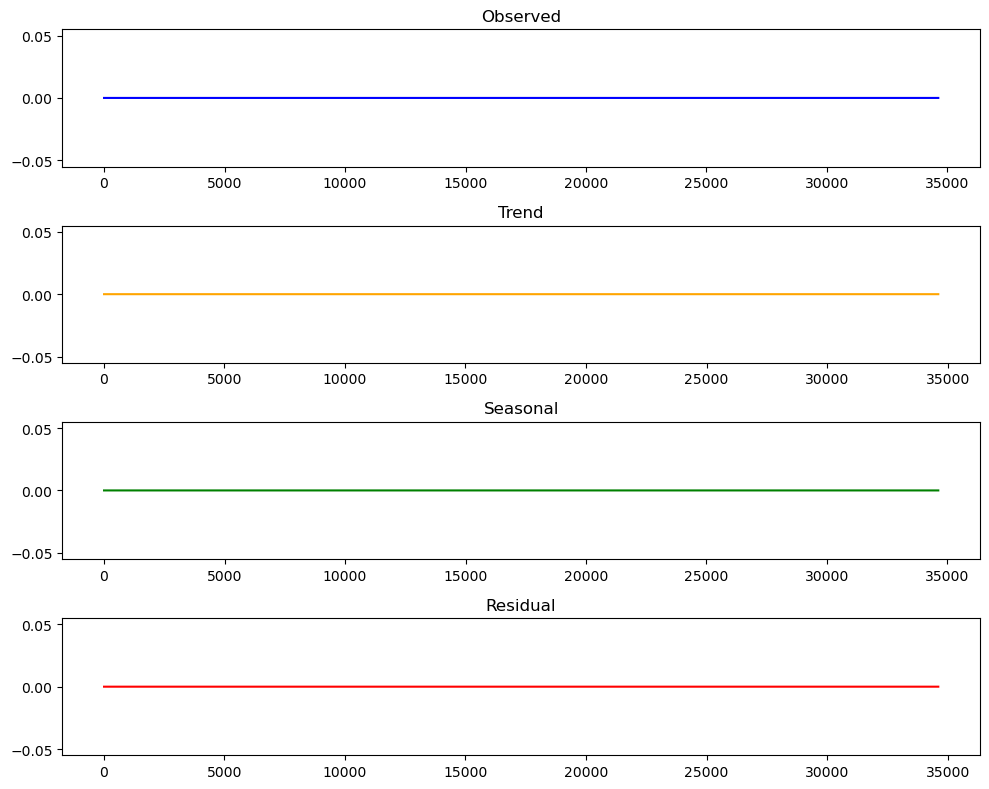

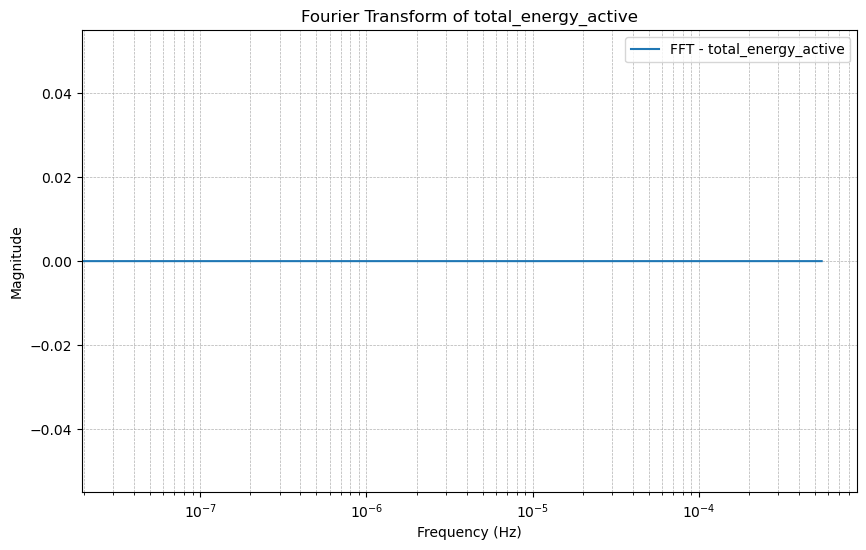

Processing time series for device 6


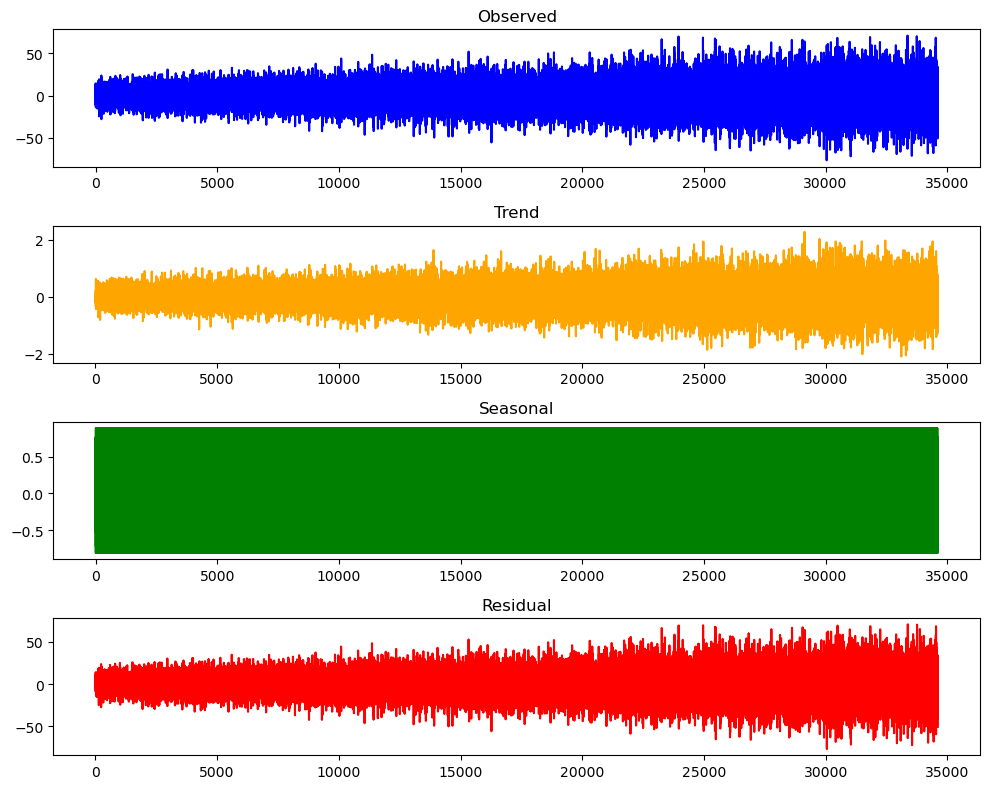

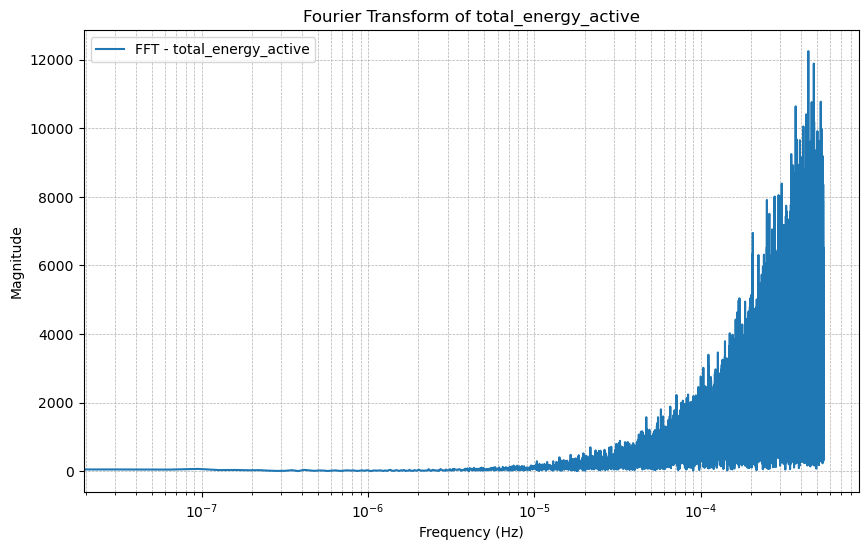

Processing time series for device 7


KeyboardInterrupt: 

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import seasonal_decompose

def plot_time_series_with_differencing_and_fft(df, variable='total_power_active', differencing=False, aggregation_period=None):
    """
    Plot the time series of a given variable and perform seasonal decomposition and FFT analysis.
    The plot is interactive for zooming and panning. Missing values are replaced by the mean and plotted in a different color.
    
    Parameters:
    - df: DataFrame with the time series data
    - variable: Column to plot (e.g., 'total_power_active')
    - differencing: If True, apply first differencing to the series
    - aggregation_period: Number of data points per aggregation group (optional)
    """
    # Ensure 'time' is in datetime format
    df['time'] = pd.to_datetime(df['time'], errors='coerce')

    # Handling NaNs by replacing them with the mean of the variable
    mean_value = df[variable].mean()
    df_cleaned = df.copy()
    
    # Identify missing values
    missing_values = df_cleaned[variable].isna()
    
    # Replace NaNs with mean values
    df_cleaned[variable] = df_cleaned[variable].fillna(mean_value)
    
    if differencing:
        # Apply differencing and drop NaN values that result from differencing
        df_cleaned[variable] = df_cleaned[variable].diff().dropna()

    # Drop any remaining NaNs after differencing (if they exist)
    df_cleaned = df_cleaned.dropna(subset=[variable])

    # Aggregation step (if aggregation_period is provided)
    if aggregation_period is not None:
        # Ensure the aggregation is based on the index (or by time if needed)
        df_cleaned = df_cleaned.iloc[:len(df_cleaned) // aggregation_period * aggregation_period]  # Ensure clean grouping
        df_cleaned = df_cleaned.groupby(np.arange(len(df_cleaned)) // aggregation_period).agg({variable: 'mean', 'time': 'first'})

    # Make sure no NaNs are left before decomposition
    if df_cleaned[variable].isna().sum() > 0:
        print(f"missing values: {df_cleaned[variable].isna().sum()}")
        raise ValueError("There are still missing values in the data after processing!")

    # Plotting time series with Plotly for interactivity
    trace_clean = go.Scatter(x=df_cleaned['time'], y=df_cleaned[variable], mode='lines', name=f'{variable}', line=dict(color='blue'))
    
    # Highlight missing values in red (original data with NaNs)
    trace_missing = go.Scatter(x=df[missing_values]['time'], 
                               y=[mean_value] * missing_values.sum(), 
                               mode='markers', 
                               name='Missing Values', 
                               marker=dict(color='red', size=10, symbol='x'))

    layout = go.Layout(
        title=f'{variable} Time Series',
        xaxis={'title': 'Time'},
        yaxis={'title': variable},
        showlegend=True
    )

    fig = go.Figure(data=[trace_clean, trace_missing], layout=layout)
    fig.update_layout(xaxis_rangeslider_visible=True)  # Adding zoom functionality
    fig.show()

    # Seasonal Decomposition using statsmodels
    decomposition = seasonal_decompose(df_cleaned[variable], model='additive', period=24)
    fig, ax = plt.subplots(4, 1, figsize=(10, 8))
    decomposition.observed.plot(ax=ax[0], title="Observed", color='blue')
    decomposition.trend.plot(ax=ax[1], title="Trend", color='orange')
    decomposition.seasonal.plot(ax=ax[2], title="Seasonal", color='green')
    decomposition.resid.plot(ax=ax[3], title="Residual", color='red')
    plt.tight_layout()
    plt.show()

    # Fourier Transform (FFT)
    signal = df_cleaned[variable]
    fs = 1 / (df_cleaned['time'].diff().dt.total_seconds().mean())  # Sampling frequency based on time diff
    n = len(signal)
    fft_result = np.fft.fft(signal)
    freq = np.fft.fftfreq(n, d=1/fs)
    
    fft_result_shifted = np.fft.fftshift(fft_result)
    freq_shifted = np.fft.fftshift(freq)
    
    plt.figure(figsize=(10, 6))
    plt.plot(freq_shifted[int(n/2):], np.abs(fft_result_shifted[int(n/2):]), label=f"FFT - {variable}")
    plt.xscale("log")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title(f"Fourier Transform of {variable}")
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.show()

# Loop through each time series for different devices
for idx, ts in enumerate(complete_time_series, start=1):
    print(f"Processing time series for device {idx}")
    plot_time_series_with_differencing_and_fft(ts, variable='total_energy_active', differencing=True, aggregation_period=3)
